In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("Car_sales.csv")

In [3]:
df["Annual Income"] = df["Annual Income"] / 100000

In [4]:
cols = ["Annual Income", "Transmission", "Body Style", "Company"]

In [5]:
X = pd.get_dummies(df[cols],
                   columns=["Transmission", "Body Style", "Company"],
                   drop_first=True).astype(int)
y = df["Price ($)"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[ 20.18, -90.01,-2458.13,..., 4347.32, 265.45, 2499.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](35,)","['Annual Income','Transmission_Manual','Body Style_Hatchback',..., 'Company_Toyota','Company_Volkswagen','Company_Volvo']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.697e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(35)


In [8]:
print("Intercept:", model.intercept_)
coef = pd.Series(model.coef_, index=X.columns)
print(coef.sort_values())

Intercept: 26968.92064846403
Company_Hyundai         -5899.074592
Company_Jeep            -4076.024517
Company_Porsche         -3109.311100
Body Style_Hatchback    -2458.132044
Company_Audi            -2057.080369
Body Style_SUV          -1996.160169
Body Style_Passenger    -1755.899495
Body Style_Sedan        -1350.944801
Company_Jaguar           -512.894238
Transmission_Manual       -90.012559
Annual Income              20.179403
Company_BMW               109.558217
Company_Volkswagen        265.452962
Company_Chevrolet         880.730999
Company_Dodge             883.794384
Company_Chrysler          959.637315
Company_Mitsubishi       1064.990530
Company_Nissan           1631.696158
Company_Mercedes-B       1656.632090
Company_Subaru           2342.012956
Company_Volvo            2499.719750
Company_Mercury          2707.083557
Company_Honda            2767.738074
Company_Infiniti         3037.023890
Company_Plymouth         3567.849317
Company_Pontiac          3956.092039
Company_F

In [9]:
y_pred = model.predict(X_test)

In [10]:
print("R2 score:", r2_score(y_test, y_pred))
print("RMSE:", mean_squared_error(y_test, y_pred) ** 0.5)

R2 score: 0.058270539032781454
RMSE: 14118.698418929414


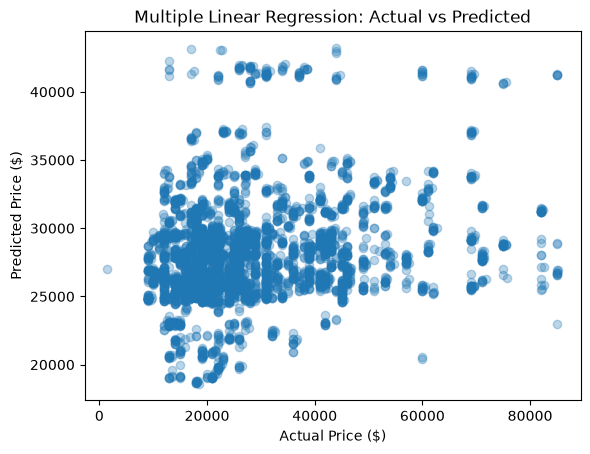

In [11]:
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Price ($)")
plt.ylabel("Predicted Price ($)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.show()